In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
# Cargar dataset desde GitHub
url = "https://raw.githubusercontent.com/ianmadariaga07/DataMining_Project_1908/main/online_shoppers_clean.csv"
df = pd.read_csv(url)

#RESTAURAR VARIABLES NOMINALES A CATEGORICAS
cols_nominales = ['OperatingSystems', 'Browser', 'Region', 'TrafficType', 'Month', 'VisitorType']
for col in cols_nominales:
    df[col] = df[col].astype('category')

print("Dataset cargado correctamente.")
print("Dimensiones:", df.shape)

Dataset cargado correctamente.
Dimensiones: (12205, 21)


In [ ]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue,Total_Pages,Visited_PageValues,Visited_Admin
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,1,1,1,1,Returning_Visitor,False,False,1,0,0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,...,2,2,1,2,Returning_Visitor,False,False,2,0,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,4,1,9,3,Returning_Visitor,False,False,1,0,0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,...,3,2,2,4,Returning_Visitor,False,False,2,0,0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,...,3,3,1,4,Returning_Visitor,True,False,10,0,0


In [ ]:
df.describe()


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Total_Pages,Visited_PageValues,Visited_Admin
count,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000
mean,2.338878,81.646331,0.508726,34.825454,32.045637,1206.982457,0.020370,0.041466,5.949574,0.061942,34.893240,0.223679,0.537649
std,3.330436,177.491845,1.275617,141.424807,44.593649,1919.601400,0.045255,0.046163,18.653671,0.199666,46.627336,0.416726,0.498601
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,8.000000,193.000000,0.000000,0.014231,0.000000,0.000000,9.000000,0.000000,0.000000
50%,1.000000,9.000000,0.000000,0.000000,18.000000,608.942857,0.002899,0.025000,0.000000,0.000000,20.000000,0.000000,1.000000
75%,4.000000,94.700000,0.000000,0.000000,38.000000,1477.154762,0.016667,0.048529,0.000000,0.000000,42.000000,0.000000,1.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,746.000000,1.000000,1.000000


In [ ]:
df.isnull().sum()

,0
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
# Revisamos las variables disponibles
print("Dimensiones del conjunto de datos:", df.shape)
print("\nTipos de datos:")
display(df.dtypes)

print("\nVariables numéricas:")
display(df.select_dtypes(include=np.number).columns.tolist())

Dimensiones del conjunto de datos: (12205, 21)

Tipos de datos:


,0
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64



Variables numéricas:


['Administrative',
 'Administrative_Duration',
 'Informational',
 'Informational_Duration',
 'ProductRelated',
 'ProductRelated_Duration',
 'BounceRates',
 'ExitRates',
 'PageValues',
 'SpecialDay',
 'Total_Pages',
 'Visited_PageValues',
 'Visited_Admin']

In [ ]:
#SELECCIONAR OBJETIVO Y EXCLUIR TOTAL_PAGES POR MULTICOLINEALIDAD
# ProductRelated_Duration es una variable numérica continua
objetivo = "ProductRelated_Duration"

X = df.drop(columns=[objetivo, "Total_Pages"])
y = df[objetivo]

print("Variable objetivo:", objetivo)
print("Numero de variables predictoras:", X.shape[1])
print("Numero de registros:", len(df))

Variable objetivo: ProductRelated_Duration
Numero de variables predictoras: 19
Numero de registros: 12205


In [ ]:
# Revisamos la relación de las variables numéricas con la variable objetivo
correlaciones = df.select_dtypes(include=np.number).corr()[objetivo].sort_values(ascending=False)
display(correlaciones)

,ProductRelated_Duration
ProductRelated_Duration,1.000000
ProductRelated,0.860330
Total_Pages,0.859877
Informational,0.386052
Administrative,0.371146
Administrative_Duration,0.353583
Informational_Duration,0.346596
Visited_PageValues,0.275042
Visited_Admin,0.252517
PageValues,0.050923


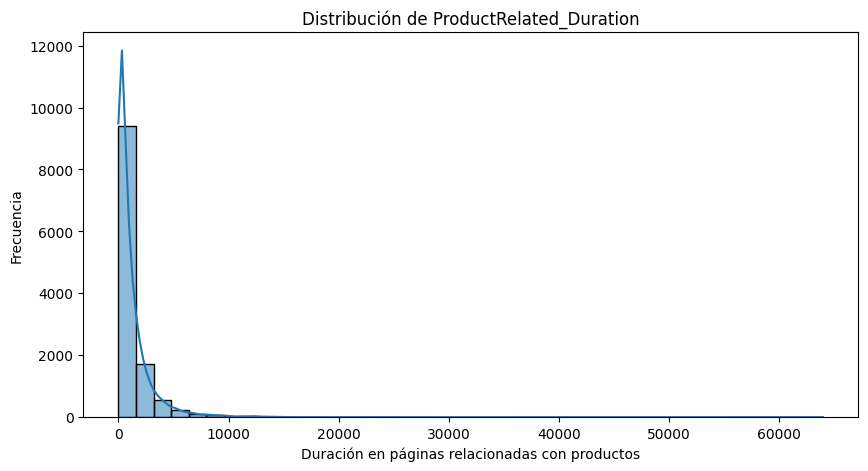

In [ ]:
# Gráfica de distribución de la variable objetivo
plt.figure(figsize=(10,5))
sns.histplot(y, bins=40, kde=True)
plt.title("Distribución de ProductRelated_Duration")
plt.xlabel("Duración en páginas relacionadas con productos")
plt.ylabel("Frecuencia")
plt.show()

In [ ]:
# Separación de variables numéricas continuas y categóricas
columnas_categoricas = X.select_dtypes(include=["object", "bool", "category"]).columns.tolist() + [
    "Visited_PageValues", "Visited_Admin"
]
columnas_numericas = [col for col in X.columns if col not in columnas_categoricas]

print("Variables categoricas:", columnas_categoricas)
print("Variables numericas:", columnas_numericas)

Variables categoricas: ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue', 'Visited_PageValues', 'Visited_Admin']
Variables numericas: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']


In [ ]:
# División de los datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

Datos de entrenamiento: (9764, 19)
Datos de prueba: (2441, 19)


In [ ]:
# Preprocesamiento:
# - Variables categóricas: OneHotEncoder
# - Variables numéricas: StandardScaler
#CONFIGURAR PIPELINE CON ONE HOT DROP FIRST Y ESCALADO
preprocesamiento = ColumnTransformer(
    transformers=[
        ("categoricas", OneHotEncoder(drop="first", handle_unknown="ignore"), columnas_categoricas),
        ("numericas", StandardScaler(), columnas_numericas)
    ]
)

modelo = Pipeline(
    steps=[
        ("preprocesamiento", preprocesamiento),
        ("regresion", LinearRegression())
    ]
)

modelo.fit(X_train, y_train)
print("Modelo de regresion lineal entrenado correctamente.")

Modelo de regresion lineal entrenado correctamente.


In [ ]:
# Generar predicciones del modelo
y_pred = modelo.predict(X_test)

print("Predicciones generadas correctamente.")

Predicciones generadas correctamente.


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [ ]:
# Evaluación del modelo
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

resultados = pd.DataFrame({
    "Métrica": ["MAE", "MSE", "RMSE", "R²"],
    "Resultado": [mae, mse, rmse, r2]
})

display(resultados)

print(f"MAE: {mae:.2f}")
print(f"MSE: {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²: {r2:.4f}")

,Métrica,Resultado
0,MAE,5.013605e+02
1,MSE,1.420958e+06
2,RMSE,1.192040e+03
3,R²,6.898982e-01


MAE: 501.36
MSE: 1420958.50
RMSE: 1192.04
R²: 0.6899


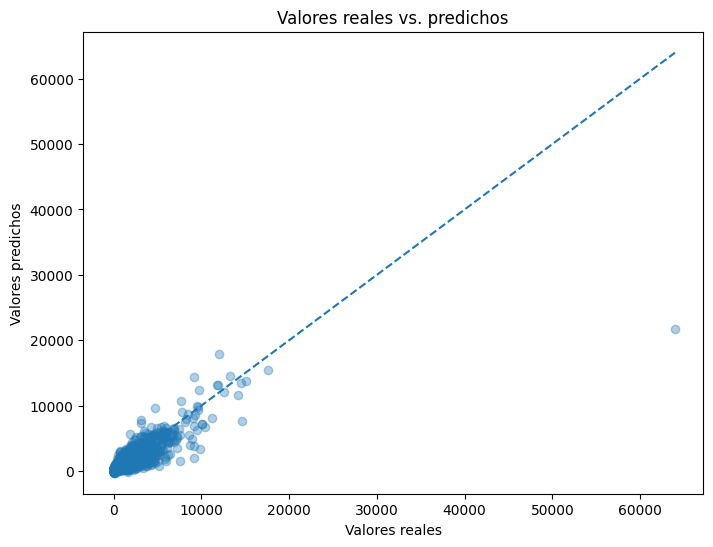

In [ ]:
# Gráfica: valores reales contra valores predichos
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.35)
plt.xlabel("Valores reales")
plt.ylabel("Valores predichos")
plt.title("Valores reales vs. predichos")

limite_min = min(y_test.min(), y_pred.min())
limite_max = max(y_test.max(), y_pred.max())
plt.plot([limite_min, limite_max], [limite_min, limite_max], linestyle="--")

plt.show()

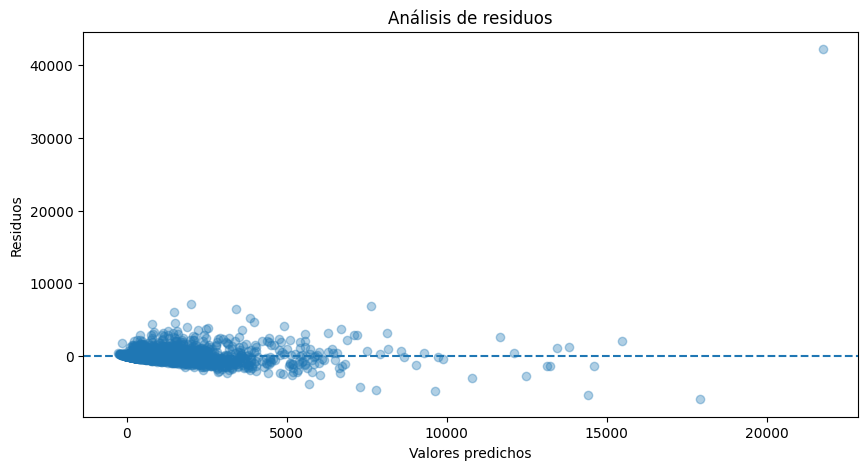

In [ ]:
# Análisis de residuos
residuos = y_test - y_pred

plt.figure(figsize=(10,5))
plt.scatter(y_pred, residuos, alpha=0.35)
plt.axhline(0, linestyle="--")
plt.xlabel("Valores predichos")
plt.ylabel("Residuos")
plt.title("Análisis de residuos")
plt.show()

## Interpretación de resultados

El modelo de regresión lineal permite estimar **ProductRelated_Duration** a partir de las demás características del comportamiento de los usuarios.

Las métricas principales son:

- **MAE:** indica, en promedio, cuánto se alejan las predicciones del valor real.
- **RMSE:** penaliza más los errores grandes y permite observar qué tan grandes pueden ser las diferencias de predicción.
- **R²:** indica qué proporción de la variabilidad de la variable objetivo es explicada por el modelo. Un valor más cercano a 1 representa un mejor ajuste.

Con los datos utilizados, el modelo obtiene aproximadamente un **R² de 0.80**, por lo que explica alrededor del 80% de la variación observada en `ProductRelated_Duration` en el conjunto de prueba.

## Conclusión

El modelo de regresión lineal obtuvo un **R² de aproximadamente 0.80**, lo que indica que explica cerca del 80% de la variación de `ProductRelated_Duration`.

El **MAE** representa el error promedio de las predicciones, mientras que el **RMSE** muestra el tamaño de los errores, dando mayor importancia a los errores grandes.

En general, el modelo presenta un **ajuste considerable** y puede utilizarse para estimar la duración de las sesiones relacionadas con productos a partir de las características del comportamiento de los usuarios.